In [4]:
%pip -q install scikit-learn pandas numpy matplotlib seaborn joblib

Dataset shape: (30139, 15)
Number of input features: 14

Class distribution:
 income
<=50K    22633
>50K      7506
Name: count, dtype: int64

Working dataset shape: (12000, 15)
Features used: 14
Target classes: 0 = <=50K, 1 = >50K

Training records: 9600
Testing records: 2400

Training Logistic Regression ...

Training Decision Tree ...

Training K-Nearest Neighbors ...

Training Gaussian Naive Bayes ...

Training Support Vector Machine ...

========== MODEL COMPARISON ==========


,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8083,0.9019,0.5799,0.8378,0.6854,0.5734
1,Support Vector Machine,0.7821,0.8968,0.5390,0.8662,0.6645,0.5476
2,Decision Tree,0.7850,0.8575,0.5456,0.8211,0.6555,0.5308
3,K-Nearest Neighbors,0.8254,0.8638,0.6679,0.5953,0.6295,0.5173
4,Gaussian Naive Bayes,0.5117,0.7065,0.3347,0.9716,0.4979,0.3197



Overall best model based on F1 Score: Logistic Regression
Logistic Regression: Accuracy=0.808, AUC=0.902, Precision=0.580, Recall=0.838, F1=0.685, MCC=0.573.
Support Vector Machine: Accuracy=0.782, AUC=0.897, Precision=0.539, Recall=0.866, F1=0.665, MCC=0.548.
Decision Tree: Accuracy=0.785, AUC=0.858, Precision=0.546, Recall=0.821, F1=0.656, MCC=0.531.
K-Nearest Neighbors: Accuracy=0.825, AUC=0.864, Precision=0.668, Recall=0.595, F1=0.630, MCC=0.517.
Gaussian Naive Bayes: Accuracy=0.512, AUC=0.707, Precision=0.335, Recall=0.972, F1=0.498, MCC=0.320.

Classification report - Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86      1802
        >50K       0.58      0.84      0.69       598

    accuracy                           0.81      2400
   macro avg       0.76      0.82      0.77      2400
weighted avg       0.85      0.81      0.82      2400



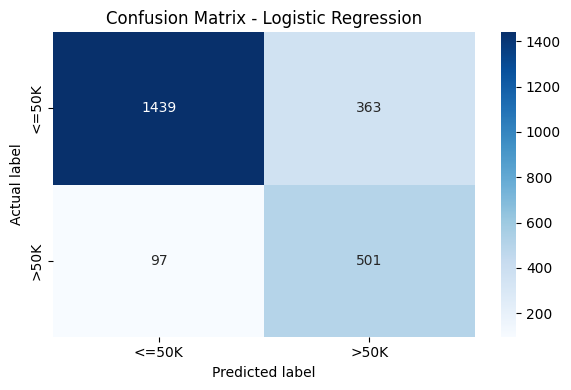


Files created:
- test_data.csv
- model_comparison_results.csv
- models/ (five trained pipelines and metadata)

Download these files from the Colab Files panel.


In [5]:

# ============================================================
# MACHINE LEARNING ASSIGNMENT 2 - TRAINING AND EVALUATION
# Dataset: UCI Adult Income (14 input features)
# Models: Logistic Regression, Decision Tree, KNN,
#         Gaussian Naive Bayes, Support Vector Machine
# ============================================================

import os, zipfile, urllib.request, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
os.makedirs("models", exist_ok=True)

# STEP 1: Download the UCI Adult dataset
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country",
    "income"
]
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
local_csv = "adult_income_raw.csv"

if not os.path.exists(local_csv):
    urllib.request.urlretrieve(url, local_csv)

df = pd.read_csv(
    local_csv, header=None, names=columns, skipinitialspace=True,
    na_values="?"
)
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["income"] = df["income"].astype(str).str.strip().str.replace(".", "", regex=False)

print("Dataset shape:", df.shape)
print("Number of input features:", len(columns) - 1)
print("\nClass distribution:\n", df["income"].value_counts())

# The complete UCI training file has more than 500 rows.
# For faster execution of all five models in a free Colab runtime,
# use a reproducible stratified sample of at most 12,000 records.
if len(df) > 12000:
    df, _ = train_test_split(
        df, train_size=12000, random_state=RANDOM_STATE,
        stratify=df["income"]
    )
    df = df.reset_index(drop=True)

X = df.drop(columns=["income"])
y = df["income"].map({"<=50K": 0, ">50K": 1})

print("\nWorking dataset shape:", df.shape)
print("Features used:", X.shape[1])
print("Target classes: 0 = <=50K, 1 = >50K")

# STEP 2: Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Dense output is required by Gaussian Naive Bayes.
try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # Compatibility with older scikit-learn versions
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot)
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# STEP 3: Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# STEP 4: Define all five classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, min_samples_split=10, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=7, weights="distance", n_jobs=-1
    ),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(
        kernel="linear", probability=True, class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

# STEP 5: Train, evaluate and save each complete preprocessing+model pipeline
results = []
trained_pipelines = {}

for model_name, classifier in models.items():
    print(f"\nTraining {model_name} ...")
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    metrics = {
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }
    results.append(metrics)
    trained_pipelines[model_name] = pipeline

    safe_name = (
        model_name.lower().replace(" ", "_").replace("-", "_")
    )
    joblib.dump(pipeline, f"models/{safe_name}.joblib")

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "AUC": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1 Score": "{:.4f}", "MCC": "{:.4f}"
}))

# Save metric table for README/report preparation
results_df.to_csv("model_comparison_results.csv", index=False)

# STEP 6: Identify the best model using F1 score
winner = results_df.iloc[0]["ML Model Name"]
print("\nOverall best model based on F1 Score:", winner)

# STEP 7: Observations (generated from the actual measured results)
for _, row in results_df.iterrows():
    print(
        f"{row['ML Model Name']}: Accuracy={row['Accuracy']:.3f}, "
        f"AUC={row['AUC']:.3f}, Precision={row['Precision']:.3f}, "
        f"Recall={row['Recall']:.3f}, F1={row['F1 Score']:.3f}, "
        f"MCC={row['MCC']:.3f}."
    )

# STEP 8: Confusion matrix and classification report for the winner
winner_pipeline = trained_pipelines[winner]
winner_pred = winner_pipeline.predict(X_test)
print(f"\nClassification report - {winner}")
print(classification_report(
    y_test, winner_pred, target_names=["<=50K", ">50K"], zero_division=0
))

cm = confusion_matrix(y_test, winner_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"Confusion Matrix - {winner}")
plt.tight_layout()
plt.show()

# STEP 9: Save the held-out test data with target column.
# Streamlit will use this file to evaluate saved models; it will NOT retrain.
test_data = X_test.copy()
test_data["income"] = y_test.map({0: "<=50K", 1: ">50K"})
test_data.to_csv("test_data.csv", index=False)

# Save metadata needed by the Streamlit app
metadata = {
    "target_column": "income",
    "positive_class": ">50K",
    "negative_class": "<=50K",
    "features": X.columns.tolist(),
    "models": list(models.keys())
}
joblib.dump(metadata, "models/metadata.joblib")

print("\nFiles created:")
print("- test_data.csv")
print("- model_comparison_results.csv")
print("- models/ (five trained pipelines and metadata)")
print("\nDownload these files from the Colab Files panel.")


In [6]:
from google.colab import files

files.download("model_comparison_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>